<a href="https://colab.research.google.com/github/madhuvanthi11/4th/blob/master/DR_Progression_Preliminary_Implementation_Added.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import torch

print("PyTorch:", torch.__version__)
print("GPU:", torch.cuda.is_available())

if torch.cuda.is_available():
    print(torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu130
GPU: True
Tesla T4


In [2]:
!pip install -q timm albumentations opencv-python-headless scikit-learn seaborn grad-cam

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 3.4 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [3]:
!pip install -q kaggle

In [4]:
import os
from getpass import getpass

os.environ["KAGGLE_API_TOKEN"] = getpass("Enter your Kaggle API token: ")

Enter your Kaggle API token: ··········


In [5]:
!kaggle competitions list -s aptos

ref                                                                deadline             category       reward  teamCount  userHasEntered  
-----------------------------------------------------------------  -------------------  ---------  ----------  ---------  --------------  
https://www.kaggle.com/competitions/aptos2019-blindness-detection  2019-09-07 23:59:00  Featured   50,000 Usd       2928            True  
https://www.kaggle.com/competitions/precio-aptos-medellin          2050-09-26 23:59:00  Community       Kudos         24           False  
https://www.kaggle.com/competitions/aptos                          2018-03-11 23:59:00  Community       Kudos         18           False  
https://www.kaggle.com/competitions/copy-of-2022-tzuchi-mi-2       2022-11-19 23:59:00  Community       Kudos          2           False  
https://www.kaggle.com/competitions/2022-tzuchi-mi                 2022-11-19 23:59:00  Community       Kudos          1           False  
https://www.kaggle.com/comp

In [6]:
!pip install -q -U kaggle

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.2/126.2 kB 5.2 MB/s eta 0:00:00


In [7]:
!kaggle competitions download -c aptos2019-blindness-detection -p /content

100% 9.51G/9.51G [01:00<00:00, 170MB/s]



In [8]:
!ls -lh /content/aptos2019-blindness-detection.zip

-rw-r--r-- 1 root root 9.6G Dec 18  2019 /content/aptos2019-blindness-detection.zip


In [9]:
!mkdir -p /content/aptos
!unzip -q /content/aptos2019-blindness-detection.zip -d /content/aptos

In [10]:
!find /content/aptos -maxdepth 2 -type f | head -20

/content/aptos/sample_submission.csv
/content/aptos/test.csv
/content/aptos/train_images/c3b15bf9b4bc.png
/content/aptos/train_images/4ed31cc07366.png
/content/aptos/train_images/6181aa9f75f4.png
/content/aptos/train_images/36a1e3c780a0.png
/content/aptos/train_images/025a169a0bb0.png
/content/aptos/train_images/885fa5fc5da8.png
/content/aptos/train_images/7350c50667c5.png
/content/aptos/train_images/57f5ad4b5b29.png
/content/aptos/train_images/a96ff96bbae5.png
/content/aptos/train_images/63c7b0265775.png
/content/aptos/train_images/260a455692b5.png
/content/aptos/train_images/6cb98da77e3e.png
/content/aptos/train_images/4ef7144e24ff.png
/content/aptos/train_images/a821b6ecef33.png
/content/aptos/train_images/780f9daaa24b.png
/content/aptos/train_images/cc839823755b.png
/content/aptos/train_images/b99c825b93c5.png
/content/aptos/train_images/77b7b71ebcc3.png


In [11]:
import os

train_dir = "/content/aptos/train_images"

print("Number of training images:",
      len(os.listdir(train_dir)))

Number of training images: 3662


In [12]:
import pandas as pd

df = pd.read_csv("/content/aptos/train.csv")

print("Number of labelled images:", len(df))
print(df.head())

Number of labelled images: 3662
        id_code  diagnosis
0  000c1434d8d7          2
1  001639a390f0          4
2  0024cdab0c1e          1
3  002c21358ce6          0
4  005b95c28852          0


In [13]:
print(df["diagnosis"].value_counts().sort_index())

diagnosis
0    1805
1     370
2     999
3     193
4     295
Name: count, dtype: int64


In [14]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

df = pd.read_csv("/content/aptos/train.csv")

image_dir = "/content/aptos/train_images"

print("Images:", len(os.listdir(image_dir)))
print("Labels:", len(df))

Images: 3662
Labels: 3662


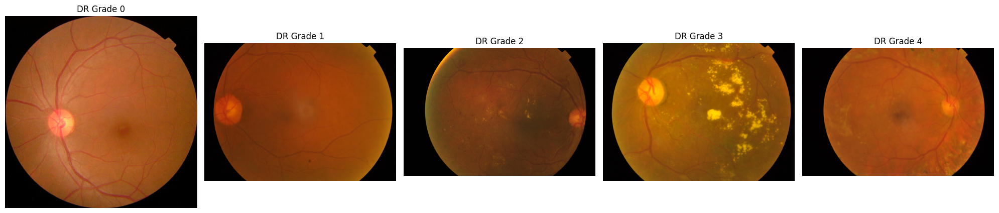

In [15]:
fig, axes = plt.subplots(1, 5, figsize=(20, 5))

for grade in range(5):

    row = df[df["diagnosis"] == grade].iloc[0]

    image_path = os.path.join(
        image_dir,
        row["id_code"] + ".png"
    )

    image = Image.open(image_path)

    axes[grade].imshow(image)
    axes[grade].set_title(f"DR Grade {grade}")
    axes[grade].axis("off")

plt.tight_layout()
plt.show()

In [16]:
from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df["diagnosis"],
    random_state=42
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["diagnosis"],
    random_state=42
)

print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))

Training: 2563
Validation: 549
Testing: 550


In [17]:
print("TRAIN")
print(train_df["diagnosis"].value_counts().sort_index())

print("\nVALIDATION")
print(val_df["diagnosis"].value_counts().sort_index())

print("\nTEST")
print(test_df["diagnosis"].value_counts().sort_index())

TRAIN
diagnosis
0    1263
1     259
2     699
3     135
4     207
Name: count, dtype: int64

VALIDATION
diagnosis
0    271
1     55
2    150
3     29
4     44
Name: count, dtype: int64

TEST
diagnosis
0    271
1     56
2    150
3     29
4     44
Name: count, dtype: int64


In [18]:
!pip install -q timm albumentations opencv-python-headless

In [19]:
import os
import cv2
import numpy as np
import pandas as pd
import torch
import timm
import albumentations as A

from torch.utils.data import Dataset, DataLoader
from albumentations.pytorch import ToTensorV2

print("PyTorch:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu130
GPU available: True
GPU: Tesla T4


In [20]:
IMG_SIZE = 224

train_transform = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE),

    A.HorizontalFlip(p=0.5),

    A.RandomBrightnessContrast(
        brightness_limit=0.2,
        contrast_limit=0.2,
        p=0.3
    ),

    A.ShiftScaleRotate(
        shift_limit=0.05,
        scale_limit=0.05,
        rotate_limit=15,
        p=0.3
    ),

    A.Normalize(
        mean=(0.485, 0.456, 0.406),
        std=(0.229, 0.224, 0.225)
    ),

    ToTensorV2()
])

/usr/local/lib/python3.13/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)


In [21]:
val_transform = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE),

    A.Normalize(
        mean=(0.485, 0.456, 0.406),
        std=(0.229, 0.224, 0.225)
    ),

    ToTensorV2()
])

In [22]:
class DRDataset(Dataset):

    def __init__(self, dataframe, image_dir, transform=None):

        self.df = dataframe.reset_index(drop=True)
        self.image_dir = image_dir
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        image_path = os.path.join(
            self.image_dir,
            row["id_code"] + ".png"
        )

        image = cv2.imread(image_path)

        if image is None:
            raise FileNotFoundError(image_path)

        image = cv2.cvtColor(
            image,
            cv2.COLOR_BGR2RGB
        )

        label = int(row["diagnosis"])

        if self.transform:
            image = self.transform(
                image=image
            )["image"]

        return image, label

In [23]:
train_dataset = DRDataset(
    train_df,
    image_dir,
    train_transform
)

val_dataset = DRDataset(
    val_df,
    image_dir,
    val_transform
)

test_dataset = DRDataset(
    test_df,
    image_dir,
    val_transform
)

print("Training:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Testing:", len(test_dataset))

Training: 2563
Validation: 549
Testing: 550


In [24]:
image, label = train_dataset[0]

print("Image shape:", image.shape)
print("Label:", label)
print("Data type:", image.dtype)

Image shape: torch.Size([3, 224, 224])
Label: 0
Data type: torch.float32


In [25]:
BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

In [26]:
images, labels = next(iter(train_loader))

print("Images:", images.shape)
print("Labels:", labels.shape)
print("Labels:", labels[:10])

Images: torch.Size([32, 3, 224, 224])
Labels: torch.Size([32])
Labels: tensor([2, 3, 3, 0, 0, 0, 2, 4, 2, 0])


In [27]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using:", device)

if device.type == "cuda":
    print(torch.cuda.get_device_name(0))

Using: cuda
Tesla T4


In [28]:
import timm
import torch

model = timm.create_model(
    "efficientnet_b0",
    pretrained=True,
    num_classes=5
)

model = model.to(device)

print(model)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


model.safetensors: reconstructing file:   0%|          |  0.00B / 21.4MB            

model.safetensors: downloading bytes:           |  0.00B            

EfficientNet(
  (conv_stem): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
  (bn1): BatchNormAct2d(
    32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True
    (drop): Identity()
    (act): SiLU(inplace=True)
  )
  (blocks): Sequential(
    (0): Sequential(
      (0): DepthwiseSeparableConv(
        (conv_dw): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
        (bn1): BatchNormAct2d(
          32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True
          (drop): Identity()
          (act): SiLU(inplace=True)
        )
        (aa): Identity()
        (se): SqueezeExcite(
          (conv_reduce): Conv2d(32, 8, kernel_size=(1, 1), stride=(1, 1))
          (act1): SiLU(inplace=True)
          (conv_expand): Conv2d(8, 32, kernel_size=(1, 1), stride=(1, 1))
          (gate): Sigmoid()
        )
        (conv_pw): Conv2d(32, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn2

In [29]:
images, labels = next(iter(train_loader))

images = images.to(device)

with torch.no_grad():
    outputs = model(images)

print("Input shape:", images.shape)
print("Output shape:", outputs.shape)

Input shape: torch.Size([32, 3, 224, 224])
Output shape: torch.Size([32, 5])


In [30]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

classes = np.sort(train_df["diagnosis"].unique())

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_df["diagnosis"]
)

print("Class weights:")
for cls, weight in zip(classes, weights):
    print(f"Class {cls}: {weight:.3f}")

Class weights:
Class 0: 0.406
Class 1: 1.979
Class 2: 0.733
Class 3: 3.797
Class 4: 2.476


In [31]:
class_weights = torch.tensor(
    weights,
    dtype=torch.float32
).to(device)

criterion = torch.nn.CrossEntropyLoss(
    weight=class_weights
)

print(class_weights)

tensor([0.4059, 1.9792, 0.7333, 3.7970, 2.4763], device='cuda:0')


In [32]:
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

In [33]:
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=2
)

In [34]:
def train_one_epoch(model, loader, criterion, optimizer):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()

        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy

In [35]:
def validate(model, loader, criterion):

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    all_labels = []
    all_predictions = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            outputs = model(images)

            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)

            correct += (predictions == labels).sum().item()

            total += labels.size(0)

            all_labels.extend(
                labels.cpu().numpy()
            )

            all_predictions.extend(
                predictions.cpu().numpy()
            )

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return (
        epoch_loss,
        epoch_accuracy,
        all_labels,
        all_predictions
    )

In [36]:
EPOCHS = 5

history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}

best_val_acc = 0.0

for epoch in range(EPOCHS):

    train_loss, train_acc = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer
    )

    val_loss, val_acc, _, _ = validate(
        model,
        val_loader,
        criterion
    )

    scheduler.step(val_acc)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

    if val_acc > best_val_acc:

        best_val_acc = val_acc

        torch.save(
            model.state_dict(),
            "/content/best_dr_model.pth"
        )

print("\nBest validation accuracy:", best_val_acc)

Epoch 1/5 | Train Loss: 1.8425 | Train Acc: 0.5103 | Val Loss: 1.4256 | Val Acc: 0.6175
Epoch 2/5 | Train Loss: 0.9509 | Train Acc: 0.7320 | Val Loss: 1.2595 | Val Acc: 0.6667
Epoch 3/5 | Train Loss: 0.6877 | Train Acc: 0.7936 | Val Loss: 1.3483 | Val Acc: 0.6903
Epoch 4/5 | Train Loss: 0.5154 | Train Acc: 0.8459 | Val Loss: 1.3200 | Val Acc: 0.7268
Epoch 5/5 | Train Loss: 0.4589 | Train Acc: 0.8631 | Val Loss: 1.4570 | Val Acc: 0.7377

Best validation accuracy: 0.7377049180327869


In [37]:
import os

print(
    "Model exists:",
    os.path.exists("/content/best_dr_model.pth")
)

print(
    "Model size:",
    os.path.getsize("/content/best_dr_model.pth") / (1024**2),
    "MB"
)

Model exists: True
Model size: 15.5950345993042 MB


In [38]:
model.load_state_dict(
    torch.load(
        "/content/best_dr_model.pth",
        map_location=device
    )
)

model.eval()

print("Best model loaded.")

Best model loaded.


In [39]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

test_loss, test_acc, y_true, y_pred = validate(
    model,
    test_loader,
    criterion
)

print("Test Accuracy:", test_acc)

print("\nWeighted Precision:",
      precision_score(
          y_true,
          y_pred,
          average="weighted",
          zero_division=0
      ))

print("\nWeighted Recall:",
      recall_score(
          y_true,
          y_pred,
          average="weighted",
          zero_division=0
      ))

print("\nWeighted F1:",
      f1_score(
          y_true,
          y_pred,
          average="weighted",
          zero_division=0
      ))

print("\nClassification Report:\n")

print(
    classification_report(
        y_true,
        y_pred,
        target_names=[
            "No DR",
            "Mild",
            "Moderate",
            "Severe",
            "Proliferative"
        ],
        zero_division=0
    )
)

Test Accuracy: 0.7618181818181818

Weighted Precision: 0.7647935846305461

Weighted Recall: 0.7618181818181818

Weighted F1: 0.76290745817137

Classification Report:

               precision    recall  f1-score   support

        No DR       0.96      0.96      0.96       271
         Mild       0.51      0.54      0.52        56
     Moderate       0.70      0.68      0.69       150
       Severe       0.38      0.31      0.34        29
Proliferative       0.35      0.41      0.38        44

     accuracy                           0.76       550
    macro avg       0.58      0.58      0.58       550
 weighted avg       0.76      0.76      0.76       550



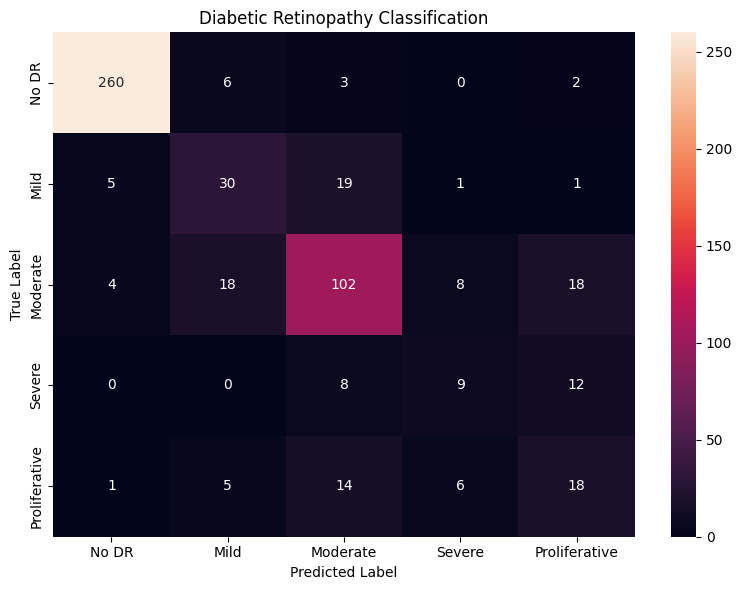

In [40]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_true, y_pred)

class_names = [
    "No DR",
    "Mild",
    "Moderate",
    "Severe",
    "Proliferative"
]

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Diabetic Retinopathy Classification")

plt.tight_layout()
plt.show()

In [41]:
def get_predictions(model, loader):

    model.eval()

    all_labels = []
    all_probs = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)

            outputs = model(images)

            probabilities = torch.softmax(
                outputs,
                dim=1
            )

            all_labels.extend(
                labels.numpy()
            )

            all_probs.extend(
                probabilities.cpu().numpy()
            )

    return (
        np.array(all_labels),
        np.array(all_probs)
    )

In [42]:
from sklearn.metrics import roc_auc_score

y_true, y_probs = get_predictions(
    model,
    test_loader
)

weighted_auc = roc_auc_score(
    y_true,
    y_probs,
    multi_class="ovr",
    average="weighted"
)

print("Weighted Multiclass AUROC:", weighted_auc)

Weighted Multiclass AUROC: 0.9393779836267157


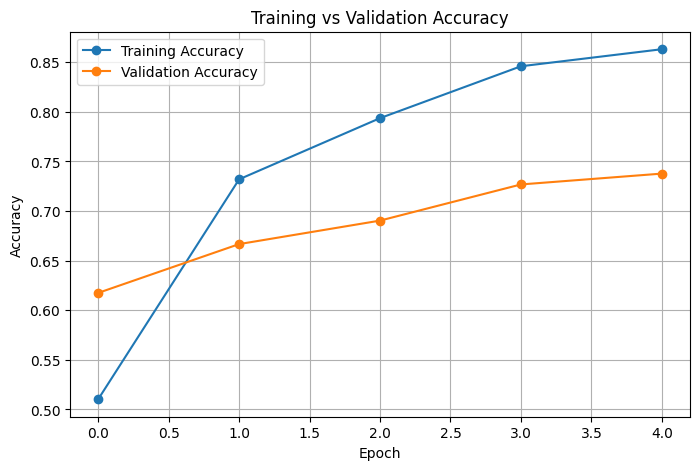

In [43]:
plt.figure(figsize=(8, 5))

plt.plot(
    history["train_acc"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    history["val_acc"],
    marker="o",
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.grid(True)

plt.show()

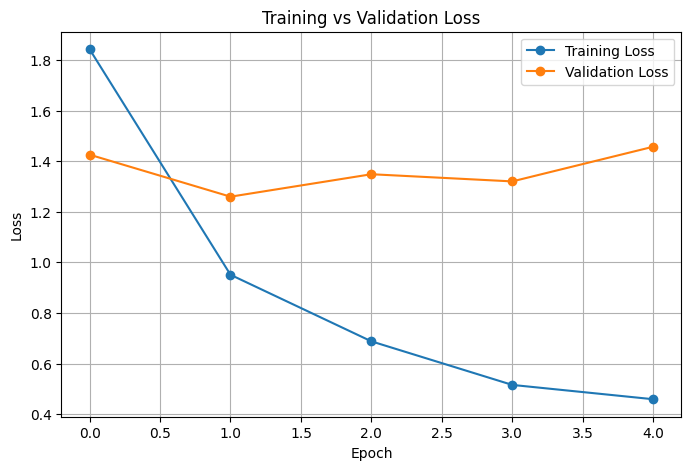

In [44]:
plt.figure(figsize=(8, 5))

plt.plot(
    history["train_loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    history["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True)

plt.show()

In [45]:
!pip install -q grad-cam

In [46]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image

In [47]:
print(model)

EfficientNet(
  (conv_stem): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
  (bn1): BatchNormAct2d(
    32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True
    (drop): Identity()
    (act): SiLU(inplace=True)
  )
  (blocks): Sequential(
    (0): Sequential(
      (0): DepthwiseSeparableConv(
        (conv_dw): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
        (bn1): BatchNormAct2d(
          32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True
          (drop): Identity()
          (act): SiLU(inplace=True)
        )
        (aa): Identity()
        (se): SqueezeExcite(
          (conv_reduce): Conv2d(32, 8, kernel_size=(1, 1), stride=(1, 1))
          (act1): SiLU(inplace=True)
          (conv_expand): Conv2d(8, 32, kernel_size=(1, 1), stride=(1, 1))
          (gate): Sigmoid()
        )
        (conv_pw): Conv2d(32, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn2

In [48]:

# Additional evaluation metrics
from sklearn.metrics import (
    f1_score,
    cohen_kappa_score,
    balanced_accuracy_score,
    classification_report
)
import numpy as np

class_names = [
    "No DR",
    "Mild",
    "Moderate",
    "Severe",
    "Proliferative DR"
]

# Ensure labels and predictions are NumPy arrays
y_true = np.asarray(y_true)
y_pred = np.asarray(y_pred)

macro_f1 = f1_score(
    y_true, y_pred,
    average="macro",
    zero_division=0
)

qwk = cohen_kappa_score(
    y_true, y_pred,
    weights="quadratic"
)

balanced_acc = balanced_accuracy_score(
    y_true, y_pred
)

print(f"Macro-F1: {macro_f1:.4f}")
print(f"Quadratic Weighted Kappa: {qwk:.4f}")
print(f"Balanced Accuracy: {balanced_acc:.4f}")

print("\nPer-class evaluation:")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1, 2, 3, 4],
    target_names=class_names,
    digits=4,
    zero_division=0
))


Macro-F1: 0.5781
Quadratic Weighted Kappa: 0.8175
Balanced Accuracy: 0.5789

Per-class evaluation:
                  precision    recall  f1-score   support

           No DR     0.9630    0.9594    0.9612       271
            Mild     0.5085    0.5357    0.5217        56
        Moderate     0.6986    0.6800    0.6892       150
          Severe     0.3750    0.3103    0.3396        29
Proliferative DR     0.3529    0.4091    0.3789        44

        accuracy                         0.7618       550
       macro avg     0.5796    0.5789    0.5781       550
    weighted avg     0.7648    0.7618    0.7629       550



In [49]:

from sklearn.metrics import roc_auc_score

# y_probs should have shape (number_of_test_images, 5)
assert y_probs.shape[1] == 5

print("Per-class One-vs-Rest AUROC:")

for class_id, class_name in enumerate(class_names):
    binary_labels = (y_true == class_id).astype(int)

    if len(np.unique(binary_labels)) < 2:
        print(f"{class_name}: AUROC undefined")
        continue

    class_auc = roc_auc_score(
        binary_labels,
        y_probs[:, class_id]
    )

    print(f"{class_name}: {class_auc:.4f}")

weighted_auc = roc_auc_score(
    y_true,
    y_probs,
    labels=[0, 1, 2, 3, 4],
    multi_class="ovr",
    average="weighted"
)

macro_auc = roc_auc_score(
    y_true,
    y_probs,
    labels=[0, 1, 2, 3, 4],
    multi_class="ovr",
    average="macro"
)

print(f"\nWeighted multiclass AUROC: {weighted_auc:.4f}")
print(f"Macro multiclass AUROC: {macro_auc:.4f}")


Per-class One-vs-Rest AUROC:
No DR: 0.9871
Mild: 0.8751
Moderate: 0.9073
Severe: 0.8715
Proliferative DR: 0.8816

Weighted multiclass AUROC: 0.9394
Macro multiclass AUROC: 0.9045


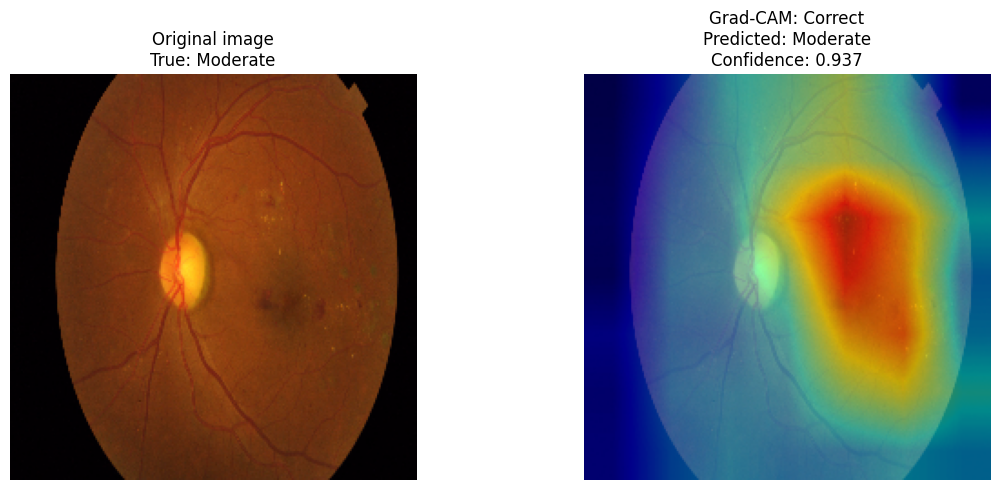

Saved: /content/gradcam_results/test_1_correct.png


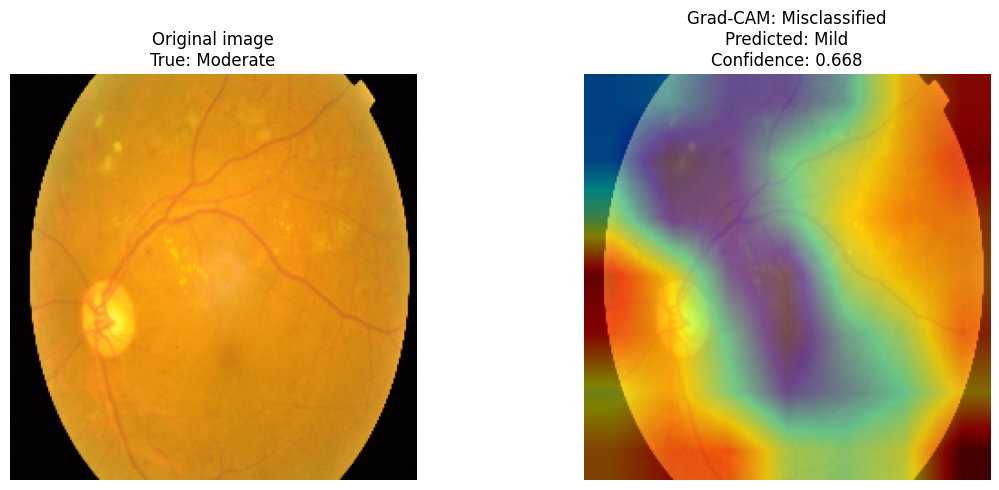

Saved: /content/gradcam_results/test_0_misclassified.png


In [50]:

import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import torch

from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image

# Confirm that the best checkpoint is loaded before explaining predictions
model.eval()

# EfficientNet-B0 final convolutional feature layer
target_layers = [model.conv_head]

# Select one correctly classified example and one misclassified example
correct_indices = np.where(y_true == y_pred)[0]
incorrect_indices = np.where(y_true != y_pred)[0]

selected_indices = []

if len(correct_indices) > 0:
    selected_indices.append(int(correct_indices[0]))

if len(incorrect_indices) > 0:
    selected_indices.append(int(incorrect_indices[0]))

if len(selected_indices) == 0:
    raise ValueError("No test predictions are available.")

# Output directory for explainability figures
os.makedirs("/content/gradcam_results", exist_ok=True)

with GradCAM(
    model=model,
    target_layers=target_layers
) as cam:

    for idx in selected_indices:

        # Obtain the corresponding test image
        row = test_df.reset_index(drop=True).iloc[idx]

        image_path = os.path.join(
            image_dir,
            row["id_code"] + ".png"
        )

        bgr_image = cv2.imread(image_path)

        if bgr_image is None:
            raise FileNotFoundError(image_path)

        rgb_image = cv2.cvtColor(
            bgr_image,
            cv2.COLOR_BGR2RGB
        )

        # Resize for display and match model input dimensions
        rgb_image = cv2.resize(
            rgb_image,
            (IMG_SIZE, IMG_SIZE)
        )

        # Convert to float [0, 1] for overlay visualization
        rgb_float = rgb_image.astype(np.float32) / 255.0

        # Apply the same validation preprocessing used for testing
        input_tensor = val_transform(
            image=rgb_image
        )["image"].unsqueeze(0).to(device)

        # Model prediction and confidence
        with torch.no_grad():
            logits = model(input_tensor)
            probabilities = torch.softmax(logits, dim=1)[0]

            predicted_class = int(
                probabilities.argmax().item()
            )

            confidence = float(
                probabilities[predicted_class].item()
            )

        true_class = int(row["diagnosis"])

        # Explain the predicted class
        targets = [
            ClassifierOutputTarget(predicted_class)
        ]

        grayscale_cam = cam(
            input_tensor=input_tensor,
            targets=targets
        )[0]

        # Overlay Grad-CAM heatmap on the retinal image
        visualization = show_cam_on_image(
            rgb_float,
            grayscale_cam,
            use_rgb=True
        )

        status = (
            "Correct"
            if predicted_class == true_class
            else "Misclassified"
        )

        plt.figure(figsize=(12, 5))

        plt.subplot(1, 2, 1)
        plt.imshow(rgb_image)
        plt.title(f"Original image\nTrue: {class_names[true_class]}")
        plt.axis("off")

        plt.subplot(1, 2, 2)
        plt.imshow(visualization)
        plt.title(
            f"Grad-CAM: {status}\n"
            f"Predicted: {class_names[predicted_class]}\n"
            f"Confidence: {confidence:.3f}"
        )
        plt.axis("off")

        plt.tight_layout()

        output_path = (
            f"/content/gradcam_results/"
            f"test_{idx}_{status.lower()}.png"
        )

        plt.savefig(
            output_path,
            dpi=300,
            bbox_inches="tight"
        )

        plt.show()
        plt.close()

        print("Saved:", output_path)


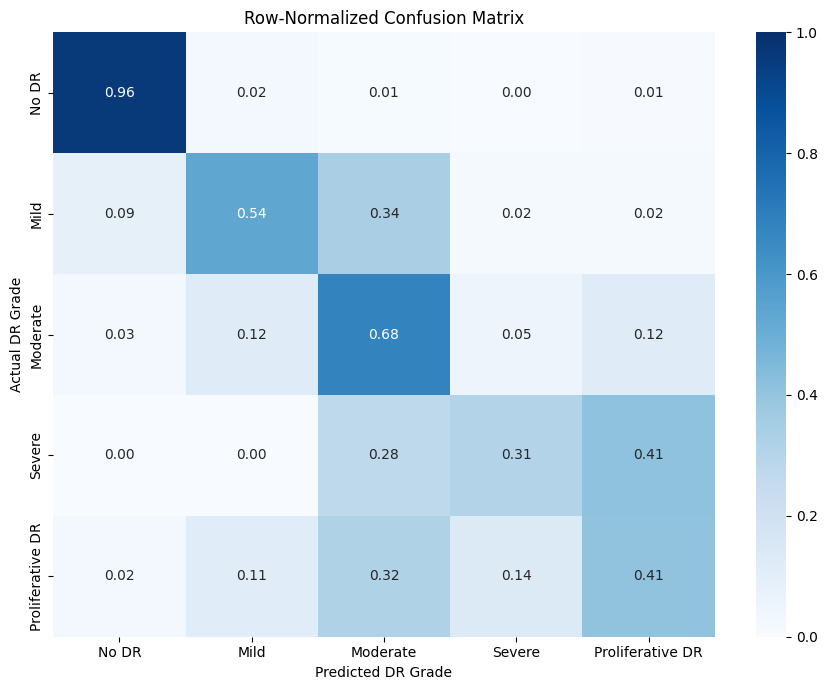

In [51]:

from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm_normalized = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1, 2, 3, 4],
    normalize="true"
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm_normalized,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    vmin=0,
    vmax=1
)

plt.xlabel("Predicted DR Grade")
plt.ylabel("Actual DR Grade")
plt.title("Row-Normalized Confusion Matrix")
plt.tight_layout()

plt.savefig(
    "/content/normalized_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [52]:

import pandas as pd
import json
import os

results_dir = "/content/dr_paper_results"
os.makedirs(results_dir, exist_ok=True)

# Save per-image predictions and probabilities
results_df = test_df.reset_index(drop=True).copy()

results_df["true_label"] = y_true
results_df["predicted_label"] = y_pred
results_df["correct"] = (y_true == y_pred)

for class_id, class_name in enumerate(class_names):
    safe_name = (
        class_name.lower()
        .replace(" ", "_")
        .replace("/", "_")
    )
    results_df[f"prob_{safe_name}"] = y_probs[:, class_id]

results_df.to_csv(
    os.path.join(results_dir, "test_predictions.csv"),
    index=False
)

# Save aggregate metrics
metrics = {
    "test_accuracy": float(np.mean(y_true == y_pred)),
    "macro_f1": float(macro_f1),
    "weighted_auroc": float(weighted_auc),
    "macro_auroc": float(macro_auc),
    "quadratic_weighted_kappa": float(qwk),
    "balanced_accuracy": float(balanced_acc)
}

with open(
    os.path.join(results_dir, "evaluation_metrics.json"),
    "w"
) as f:
    json.dump(metrics, f, indent=4)

print("Results saved to:", results_dir)
print(json.dumps(metrics, indent=4))


Results saved to: /content/dr_paper_results
{
    "test_accuracy": 0.7618181818181818,
    "macro_f1": 0.5781362648018342,
    "weighted_auroc": 0.9393779836267157,
    "macro_auroc": 0.9045301407296928,
    "quadratic_weighted_kappa": 0.8174756457329626,
    "balanced_accuracy": 0.5789119232974685
}


Test predictions collected: 550

No DR: 260 correct, 11 misclassified


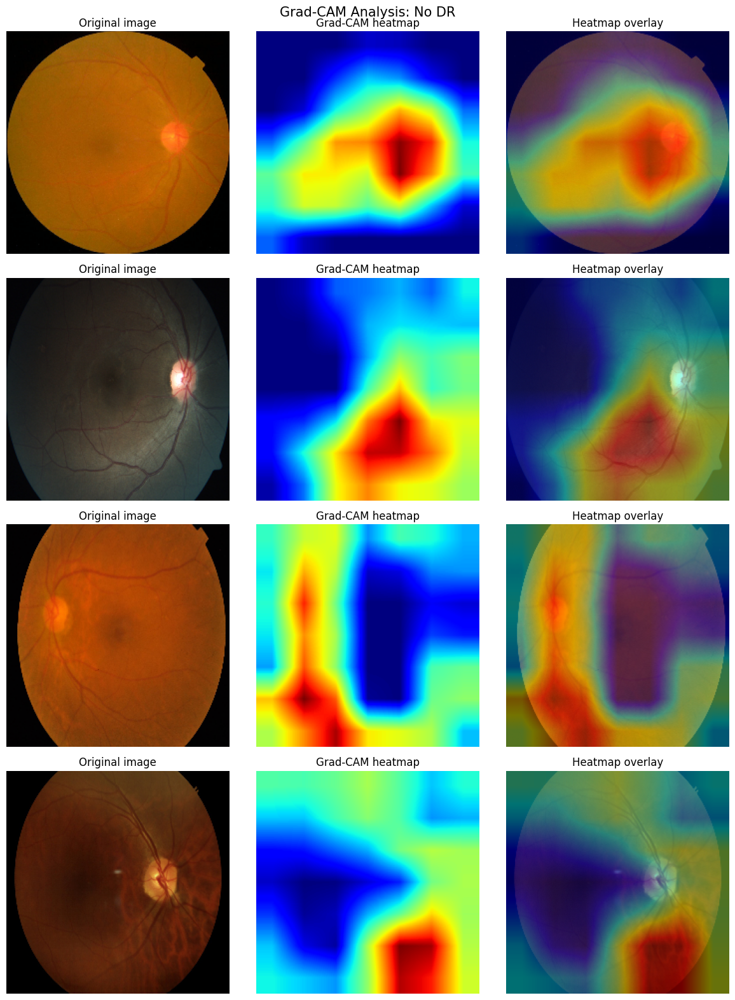


Mild DR: 30 correct, 26 misclassified


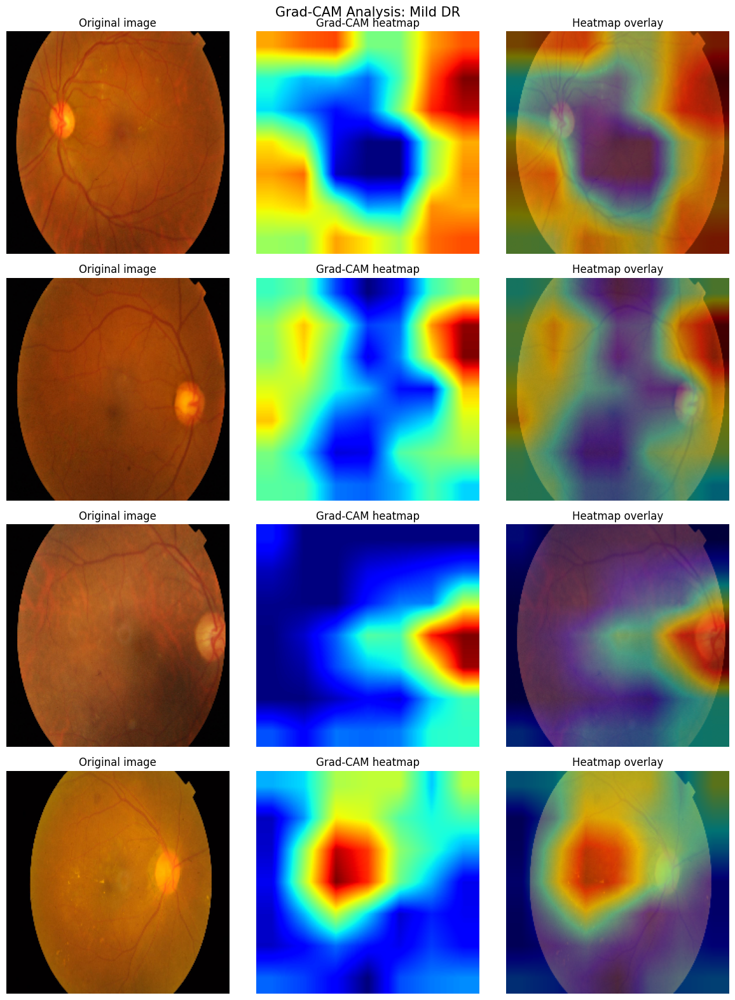


Moderate DR: 102 correct, 48 misclassified


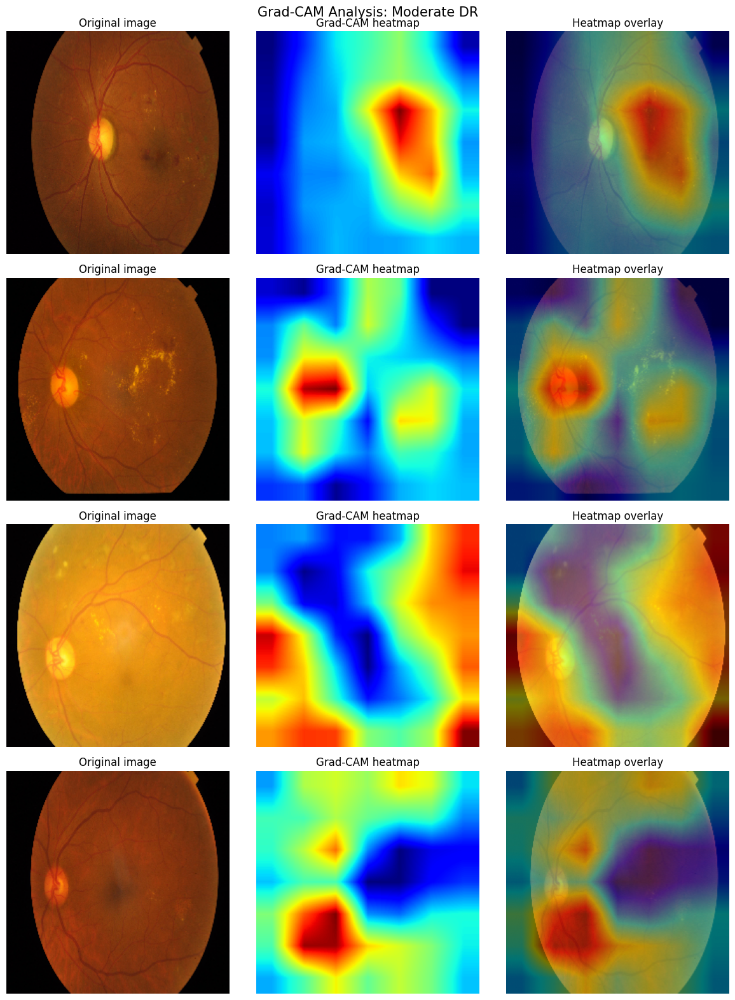


Severe DR: 9 correct, 20 misclassified


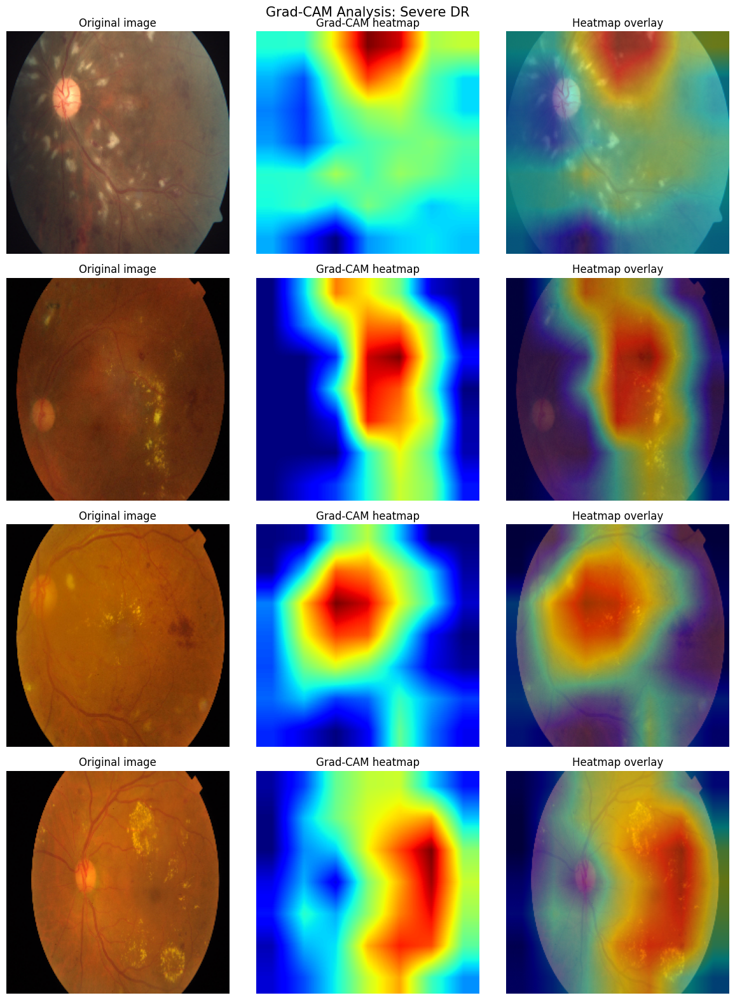


Proliferative DR: 18 correct, 26 misclassified


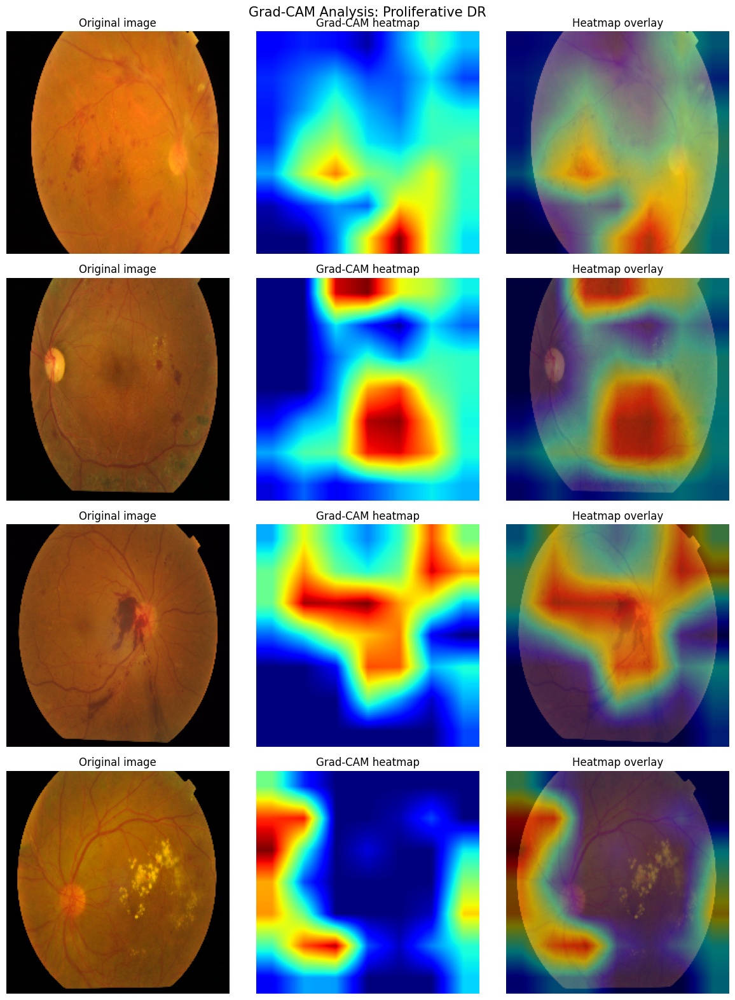

,test_index,true_class,true_label,predicted_class,predicted_label,case_type,predicted_confidence,image_id
0,4,0,No DR,0,No DR,Correct,0.999470,d9ad2a0ec026
1,5,0,No DR,0,No DR,Correct,0.998947,c80b0f27541a
2,67,0,No DR,2,Moderate DR,Misclassified,0.437333,d7e5fe5245e0
3,72,0,No DR,1,Mild DR,Misclassified,0.746443,7526cf435753
4,22,1,Mild DR,1,Mild DR,Correct,0.987610,01b3aed3ed4c
5,26,1,Mild DR,1,Mild DR,Correct,0.998688,3ee17aa12e46
6,2,1,Mild DR,2,Moderate DR,Misclassified,0.667856,ca7140ecf389
7,10,1,Mild DR,2,Moderate DR,Misclassified,0.992686,a28bfb772f50
8,1,2,Moderate DR,2,Moderate DR,Correct,0.937316,7877be80901c
9,6,2,Moderate DR,2,Moderate DR,Correct,0.939074,d2c6b99ef62c



Grad-CAM analysis saved to: /content/dr_paper_results/gradcam_analysis


In [53]:

import os
import cv2
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from PIL import Image

# ------------------------------------------
# 1. Create output folders
# ------------------------------------------
OUTPUT_DIR = "/content/dr_paper_results/gradcam_analysis"
os.makedirs(OUTPUT_DIR, exist_ok=True)

CLASS_NAMES = {
    0: "No DR",
    1: "Mild DR",
    2: "Moderate DR",
    3: "Severe DR",
    4: "Proliferative DR"
}

model.eval()

# ------------------------------------------
# 2. Obtain predictions in test-set order
# ------------------------------------------
all_true = []
all_pred = []
all_probs = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        logits = model(images)
        probabilities = torch.softmax(logits, dim=1)
        predictions = logits.argmax(dim=1)

        all_true.extend(labels.cpu().numpy())
        all_pred.extend(predictions.cpu().numpy())
        all_probs.extend(probabilities.cpu().numpy())

all_true = np.asarray(all_true)
all_pred = np.asarray(all_pred)
all_probs = np.asarray(all_probs)

assert len(all_true) == len(test_df), (
    "Prediction count and test_df length do not match. "
    "Check that test_loader uses test_dataset with shuffle=False."
)

print("Test predictions collected:", len(all_true))

# ------------------------------------------
# 3. Grad-CAM for one test image
# ------------------------------------------
def generate_gradcam(input_tensor, target_class):
    activations = []
    gradients = []

    target_layer = model.conv_head

    def forward_hook(module, inputs, output):
        activations.append(output)

        # Capture gradients flowing through the layer output
        output.register_hook(
            lambda grad: gradients.append(grad)
        )

    handle = target_layer.register_forward_hook(forward_hook)

    try:
        model.zero_grad(set_to_none=True)

        # Gradients are required for Grad-CAM
        with torch.enable_grad():
            logits = model(input_tensor)
            score = logits[0, target_class]
            score.backward()

        activation = activations[0].detach()[0]
        gradient = gradients[0].detach()[0]

        # Average gradients across spatial dimensions
        weights = gradient.mean(dim=(1, 2))

        # Weighted combination of feature maps
        cam = (weights[:, None, None] * activation).sum(dim=0)
        cam = torch.relu(cam)

        cam = cam.cpu().numpy()
        cam -= cam.min()

        if cam.max() > 0:
            cam /= cam.max()

        cam = cv2.resize(
            cam, (224, 224),
            interpolation=cv2.INTER_LINEAR
        )

        return cam

    finally:
        handle.remove()
        model.zero_grad(set_to_none=True)

# ------------------------------------------
# 4. Convert normalized tensor to RGB image
# ------------------------------------------
MEAN = np.array([0.485, 0.456, 0.406])
STD = np.array([0.229, 0.224, 0.225])

def tensor_to_rgb(tensor):
    image = tensor.detach().cpu().permute(1, 2, 0).numpy()
    image = image * STD + MEAN
    return np.clip(image, 0, 1)

# ------------------------------------------
# 5. Select examples and create heatmaps
# ------------------------------------------
summary_rows = []

for true_class in range(5):

    correct_indices = np.where(
        (all_true == true_class) &
        (all_pred == true_class)
    )[0]

    wrong_indices = np.where(
        (all_true == true_class) &
        (all_pred != true_class)
    )[0]

    # Up to two examples of each type
    selected = [
        (idx, "Correct") for idx in correct_indices[:2]
    ] + [
        (idx, "Misclassified") for idx in wrong_indices[:2]
    ]

    print(
        f"\n{CLASS_NAMES[true_class]}: "
        f"{len(correct_indices)} correct, "
        f"{len(wrong_indices)} misclassified"
    )

    if not selected:
        print("No examples available for this class.")
        continue

    fig, axes = plt.subplots(
        len(selected), 3,
        figsize=(12, 4 * len(selected)),
        squeeze=False
    )

    for row_num, (idx, case_type) in enumerate(selected):

        # Use the same ordering as test_df and test_dataset
        image_tensor, label = test_dataset[idx]
        input_tensor = image_tensor.unsqueeze(0).to(device)

        predicted_class = int(all_pred[idx])
        confidence = float(all_probs[idx, predicted_class])

        # Explain the class predicted by the model.
        # For correct predictions, this is the true class too.
        cam = generate_gradcam(
            input_tensor,
            target_class=predicted_class
        )

        original = tensor_to_rgb(image_tensor)

        heatmap = cv2.applyColorMap(
            np.uint8(255 * cam),
            cv2.COLORMAP_JET
        )
        heatmap = cv2.cvtColor(
            heatmap, cv2.COLOR_BGR2RGB
        ) / 255.0

        overlay = np.clip(
            0.55 * original + 0.45 * heatmap,
            0, 1
        )

        axes[row_num, 0].imshow(original)
        axes[row_num, 0].set_title("Original image")

        axes[row_num, 1].imshow(cam, cmap="jet")
        axes[row_num, 1].set_title("Grad-CAM heatmap")

        axes[row_num, 2].imshow(overlay)
        axes[row_num, 2].set_title("Heatmap overlay")

        for ax in axes[row_num]:
            ax.axis("off")

        title = (
            f"{case_type} | True: {CLASS_NAMES[true_class]} | "
            f"Predicted: {CLASS_NAMES[predicted_class]} | "
            f"Confidence: {confidence:.3f}"
        )
        axes[row_num, 0].set_ylabel(
            title, fontsize=9
        )

        # Save each case separately too
        filename = (
            f"true_{true_class}_pred_{predicted_class}_"
            f"{case_type.lower()}_testidx_{idx}.png"
        )

        plt.imsave(
            os.path.join(OUTPUT_DIR, filename),
            overlay
        )

        summary_rows.append({
            "test_index": int(idx),
            "true_class": true_class,
            "true_label": CLASS_NAMES[true_class],
            "predicted_class": predicted_class,
            "predicted_label": CLASS_NAMES[predicted_class],
            "case_type": case_type,
            "predicted_confidence": confidence,
            "image_id": test_df.iloc[idx]["id_code"]
        })

    fig.suptitle(
        f"Grad-CAM Analysis: {CLASS_NAMES[true_class]}",
        fontsize=15
    )
    plt.tight_layout()

    class_filename = f"gradcam_class_{true_class}.png"
    fig.savefig(
        os.path.join(OUTPUT_DIR, class_filename),
        dpi=200,
        bbox_inches="tight"
    )
    plt.show()
    plt.close(fig)

# ------------------------------------------
# 6. Save a record of selected examples
# ------------------------------------------
summary_df = pd.DataFrame(summary_rows)

summary_df.to_csv(
    os.path.join(OUTPUT_DIR, "gradcam_case_summary.csv"),
    index=False
)

display(summary_df)

print("\nGrad-CAM analysis saved to:", OUTPUT_DIR)


Multiclass Brier score: 0.3636
Expected Calibration Error (10 bins): 0.1280


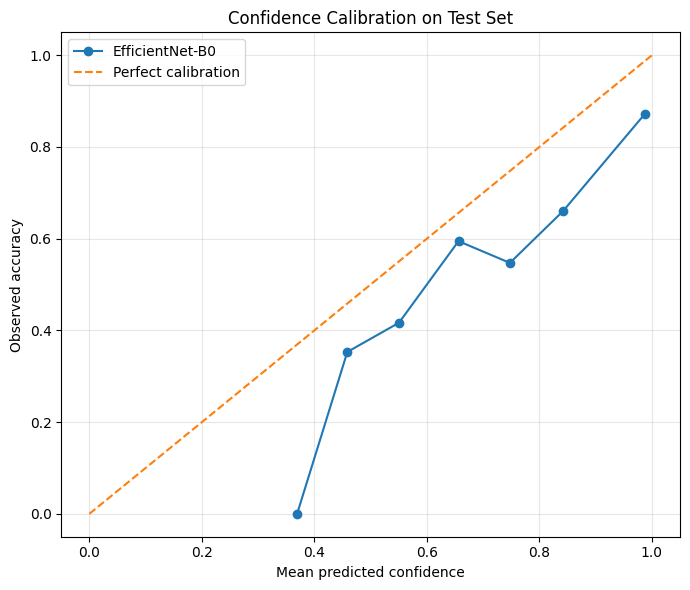

In [54]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

df = pd.read_csv(
    "/content/dr_paper_results/test_predictions.csv"
)

prob_cols = [
    "prob_no_dr",
    "prob_mild",
    "prob_moderate",
    "prob_severe",
    "prob_proliferative_dr"
]

y_true = df["true_label"].to_numpy(dtype=int)
y_pred = df["predicted_label"].to_numpy(dtype=int)
probs = df[prob_cols].to_numpy(dtype=float)

# Confidence in the model's selected class
confidence = probs.max(axis=1)
correct = (y_true == y_pred).astype(int)

# Multiclass Brier score, using one-hot target labels
one_hot = np.eye(5)[y_true]
brier_score = np.mean(np.sum((probs - one_hot) ** 2, axis=1))

# Expected Calibration Error (ECE), using 10 equal-width bins
bin_edges = np.linspace(0, 1, 11)
ece = 0.0

for i in range(10):
    if i == 9:
        mask = (confidence >= bin_edges[i]) & (
            confidence <= bin_edges[i + 1]
        )
    else:
        mask = (confidence >= bin_edges[i]) & (
            confidence < bin_edges[i + 1]
        )

    if mask.sum() > 0:
        bin_accuracy = correct[mask].mean()
        bin_confidence = confidence[mask].mean()
        ece += mask.mean() * abs(bin_accuracy - bin_confidence)

print(f"Multiclass Brier score: {brier_score:.4f}")
print(f"Expected Calibration Error (10 bins): {ece:.4f}")

# Reliability diagram: confidence vs observed accuracy
observed_accuracy, mean_confidence = calibration_curve(
    correct,
    confidence,
    n_bins=10,
    strategy="uniform"
)

plt.figure(figsize=(7, 6))
plt.plot(mean_confidence, observed_accuracy, marker="o",
         label="EfficientNet-B0")
plt.plot([0, 1], [0, 1], linestyle="--",
         label="Perfect calibration")
plt.xlabel("Mean predicted confidence")
plt.ylabel("Observed accuracy")
plt.title("Confidence Calibration on Test Set")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "/content/dr_paper_results/calibration_plot.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


In [55]:

import numpy as np
import pandas as pd

df = pd.read_csv(
    "/content/dr_paper_results/test_predictions.csv"
)

prob_cols = [
    "prob_no_dr",
    "prob_mild",
    "prob_moderate",
    "prob_severe",
    "prob_proliferative_dr"
]

probs = df[prob_cols].to_numpy(dtype=float)
y_true = df["true_label"].to_numpy(dtype=int)
y_pred = df["predicted_label"].to_numpy(dtype=int)

confidence = probs.max(axis=1)
correct = (y_true == y_pred).astype(int)

# Ten equal-width confidence bins
edges = np.linspace(0, 1, 11)
rows = []

for i in range(10):
    if i == 9:
        mask = (confidence >= edges[i]) & (confidence <= edges[i + 1])
    else:
        mask = (confidence >= edges[i]) & (confidence < edges[i + 1])

    n = int(mask.sum())

    if n:
        rows.append({
            "confidence_bin": f"{edges[i]:.1f}-{edges[i+1]:.1f}",
            "count": n,
            "mean_confidence": confidence[mask].mean(),
            "observed_accuracy": correct[mask].mean(),
            "calibration_gap": (
                confidence[mask].mean() - correct[mask].mean()
            )
        })

bin_table = pd.DataFrame(rows)
display(bin_table.round(4))

# Multiclass Brier score
one_hot = np.eye(len(prob_cols))[y_true]
brier = np.mean(np.sum((probs - one_hot) ** 2, axis=1))

# Expected Calibration Error (ECE)
ece = sum(
    row["count"] / len(df) * abs(row["calibration_gap"])
    for _, row in bin_table.iterrows()
)

print(f"ECE (10 equal-width bins): {ece:.4f}")
print(f"Multiclass Brier score: {brier:.4f}")
print(f"Total samples in bins: {bin_table['count'].sum()}")


,confidence_bin,count,mean_confidence,observed_accuracy,calibration_gap
0,0.3-0.4,3,0.3693,0.0000,0.3693
1,0.4-0.5,17,0.4585,0.3529,0.1056
2,0.5-0.6,24,0.5504,0.4167,0.1337
3,0.6-0.7,37,0.6563,0.5946,0.0617
4,0.7-0.8,53,0.7476,0.5472,0.2004
5,0.8-0.9,50,0.8420,0.6600,0.1820
6,0.9-1.0,366,0.9871,0.8716,0.1156


ECE (10 equal-width bins): 0.1280
Multiclass Brier score: 0.3636
Total samples in bins: 550


In [56]:

print("Model available:", "model" in globals())
print("Validation loader available:", "val_loader" in globals())
print("Test loader available:", "test_loader" in globals())
print("Device:", device if "device" in globals() else "not defined")


Model available: True
Validation loader available: True
Test loader available: True
Device: cuda


In [57]:

import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
from sklearn.metrics import accuracy_score
from scipy.optimize import minimize_scalar

model.eval()

def collect_logits_and_labels(loader):
    all_logits = []
    all_labels = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            logits = model(images)

            all_logits.append(logits.detach().cpu())
            all_labels.append(labels.detach().cpu())

    return (
        torch.cat(all_logits),
        torch.cat(all_labels).long()
    )

# Collect validation and test logits
val_logits, val_labels = collect_logits_and_labels(val_loader)
test_logits, test_labels = collect_logits_and_labels(test_loader)

# Fit temperature on validation data only
def validation_nll(log_temperature):
    temperature = np.exp(log_temperature)
    loss = F.cross_entropy(
        val_logits / temperature,
        val_labels
    )
    return loss.item()

result = minimize_scalar(
    validation_nll,
    bounds=(-3, 3),
    method="bounded"
)

temperature = float(np.exp(result.x))

print(f"Learned temperature: {temperature:.4f}")
print(f"Validation NLL before: {F.cross_entropy(val_logits, val_labels).item():.4f}")
print(f"Validation NLL after:  {F.cross_entropy(val_logits / temperature, val_labels).item():.4f}")

# Test probabilities before and after calibration
test_probs_before = torch.softmax(test_logits, dim=1).numpy()
test_probs_after = torch.softmax(
    test_logits / temperature, dim=1
).numpy()

y_true = test_labels.numpy()
pred_before = test_probs_before.argmax(axis=1)
pred_after = test_probs_after.argmax(axis=1)

print(f"\nTest accuracy before: {accuracy_score(y_true, pred_before):.4%}")
print(f"Test accuracy after:  {accuracy_score(y_true, pred_after):.4%}")

def calibration_metrics(probs, labels, n_bins=10):
    confidence = probs.max(axis=1)
    predictions = probs.argmax(axis=1)
    correct = (predictions == labels).astype(float)

    edges = np.linspace(0, 1, n_bins + 1)
    ece = 0.0

    for i in range(n_bins):
        if i == n_bins - 1:
            mask = (confidence >= edges[i]) & (confidence <= edges[i + 1])
        else:
            mask = (confidence >= edges[i]) & (confidence < edges[i + 1])

        if mask.any():
            ece += mask.mean() * abs(
                correct[mask].mean() - confidence[mask].mean()
            )

    one_hot = np.eye(probs.shape[1])[labels]
    brier = np.mean(np.sum((probs - one_hot) ** 2, axis=1))

    return ece, brier

ece_before, brier_before = calibration_metrics(
    test_probs_before, y_true
)
ece_after, brier_after = calibration_metrics(
    test_probs_after, y_true
)

print(f"\nTest ECE before:    {ece_before:.4f}")
print(f"Test ECE after:     {ece_after:.4f}")
print(f"Test Brier before:  {brier_before:.4f}")
print(f"Test Brier after:   {brier_after:.4f}")


Learned temperature: 2.2509
Validation NLL before: 0.8759
Validation NLL after:  0.6632

Test accuracy before: 76.1818%
Test accuracy after:  76.1818%

Test ECE before:    0.1280
Test ECE after:     0.0326
Test Brier before:  0.3636
Test Brier after:   0.3315


In [58]:

import os
import json
import numpy as np
import pandas as pd

output_dir = "/content/dr_paper_results/temperature_scaling"
os.makedirs(output_dir, exist_ok=True)

# Save calibrated test probabilities and predictions
class_names = [
    "No DR", "Mild DR", "Moderate DR",
    "Severe DR", "Proliferative DR"
]

calibrated_df = pd.DataFrame({
    "true_label": y_true,
    "predicted_label_before": pred_before,
    "predicted_label_after": pred_after,
    "confidence_before": test_probs_before.max(axis=1),
    "confidence_after": test_probs_after.max(axis=1),
    "correct_before": pred_before == y_true,
    "correct_after": pred_after == y_true
})

for i, name in enumerate(class_names):
    safe_name = name.lower().replace(" ", "_")
    calibrated_df[f"prob_before_{safe_name}"] = test_probs_before[:, i]
    calibrated_df[f"prob_after_{safe_name}"] = test_probs_after[:, i]

calibrated_df.to_csv(
    os.path.join(output_dir, "calibrated_test_predictions.csv"),
    index=False
)

metrics = {
    "temperature": float(temperature),
    "validation_nll_before": float(
        F.cross_entropy(val_logits, val_labels).item()
    ),
    "validation_nll_after": float(
        F.cross_entropy(val_logits / temperature, val_labels).item()
    ),
    "test_accuracy_before": float(accuracy_score(y_true, pred_before)),
    "test_accuracy_after": float(accuracy_score(y_true, pred_after)),
    "test_ece_before": float(ece_before),
    "test_ece_after": float(ece_after),
    "test_brier_before": float(brier_before),
    "test_brier_after": float(brier_after)
}

with open(
    os.path.join(output_dir, "temperature_scaling_metrics.json"),
    "w"
) as f:
    json.dump(metrics, f, indent=4)

print("Saved calibrated predictions and metrics to:", output_dir)


Saved calibrated predictions and metrics to: /content/dr_paper_results/temperature_scaling


In [59]:

import pandas as pd
import numpy as np
import torch

csv_path = "/content/dr_paper_results/test_predictions.csv"
original = pd.read_csv(csv_path)

# Predictions from the temperature-scaling experiment
logit_true = test_labels.cpu().numpy()
logit_pred = test_logits.argmax(dim=1).cpu().numpy()

csv_true = original["true_label"].to_numpy(dtype=int)
csv_pred = original["predicted_label"].to_numpy(dtype=int)

print("=== Dataset consistency ===")
print("CSV samples:", len(original))
print("Logit samples:", len(logit_true))
print("CSV labels match loader order:",
      len(csv_true) == len(logit_true)
      and np.array_equal(csv_true, logit_true))

if len(csv_true) == len(logit_true):
    print("CSV predictions matching current model:",
          np.mean(csv_pred == logit_pred), "fraction")

    print("\n=== Accuracy comparison ===")
    print(f"Original CSV accuracy: {(csv_true == csv_pred).mean():.4%}")
    print(f"Current logits accuracy: {(logit_true == logit_pred).mean():.4%}")

    print("\nCSV correct, current model incorrect:",
          int(np.sum((csv_true == csv_pred) & (logit_true != logit_pred))))
    print("CSV incorrect, current model correct:",
          int(np.sum((csv_true != csv_pred) & (logit_true == logit_pred))))
else:
    print("Sample counts differ; check the test dataset and loader.")


=== Dataset consistency ===
CSV samples: 550
Logit samples: 550
CSV labels match loader order: True
CSV predictions matching current model: 1.0 fraction

=== Accuracy comparison ===
Original CSV accuracy: 76.1818%
Current logits accuracy: 76.1818%

CSV correct, current model incorrect: 0
CSV incorrect, current model correct: 0


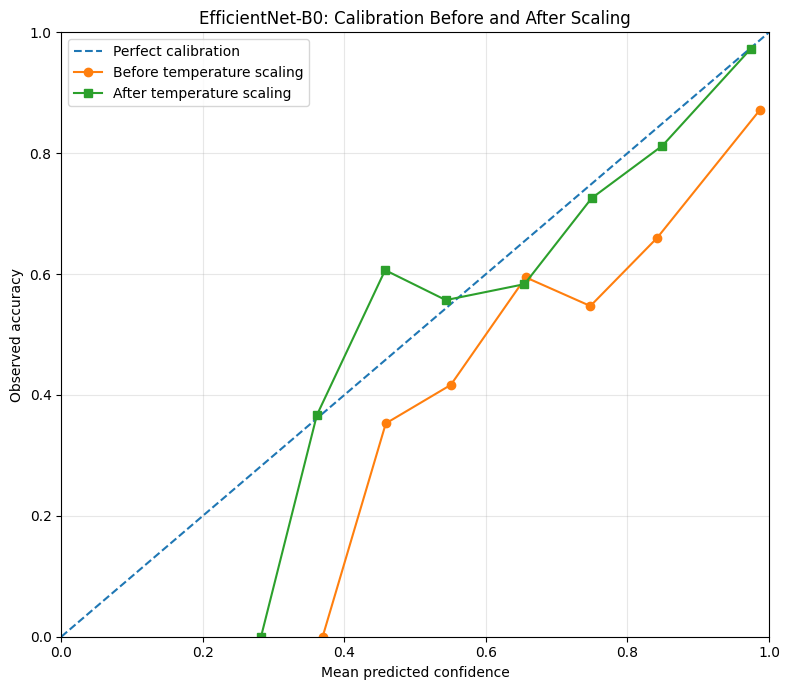

Saved figure to: /content/dr_paper_results/temperature_scaling/calibration_comparison.png


In [60]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve

def get_reliability_data(probs, labels, n_bins=10):
    confidence = probs.max(axis=1)
    predictions = probs.argmax(axis=1)
    correct = (predictions == labels).astype(int)

    edges = np.linspace(0, 1, n_bins + 1)
    mean_confidence, observed_accuracy, counts = [], [], []

    for i in range(n_bins):
        if i == n_bins - 1:
            mask = (confidence >= edges[i]) & (confidence <= edges[i+1])
        else:
            mask = (confidence >= edges[i]) & (confidence < edges[i+1])

        if mask.any():
            mean_confidence.append(confidence[mask].mean())
            observed_accuracy.append(correct[mask].mean())
            counts.append(mask.sum())

    return (
        np.array(mean_confidence),
        np.array(observed_accuracy),
        np.array(counts)
    )

conf_before, acc_before, counts_before = get_reliability_data(
    test_probs_before, y_true
)
conf_after, acc_after, counts_after = get_reliability_data(
    test_probs_after, y_true
)

fig, ax = plt.subplots(figsize=(8, 7))

ax.plot([0, 1], [0, 1], "--", label="Perfect calibration")
ax.plot(
    conf_before, acc_before, "o-",
    label="Before temperature scaling"
)
ax.plot(
    conf_after, acc_after, "s-",
    label="After temperature scaling"
)

ax.set_xlabel("Mean predicted confidence")
ax.set_ylabel("Observed accuracy")
ax.set_title("EfficientNet-B0: Calibration Before and After Scaling")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()

path = "/content/dr_paper_results/temperature_scaling/calibration_comparison.png"
fig.savefig(path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved figure to:", path)


=== FINAL METRICS ===


,Metric,Before temperature scaling,After temperature scaling
0,Accuracy,0.7618,0.7618
1,Balanced accuracy,0.5789,0.5789
2,Macro precision,0.5796,0.5796
3,Macro recall,0.5789,0.5789
4,Macro F1,0.5781,0.5781
5,Weighted F1,0.7629,0.7629
6,Quadratic weighted kappa,0.8175,0.8175
7,Macro AUROC (OvR),0.9045,0.9074
8,ECE (10 bins),0.1280,0.0326
9,Multiclass Brier score,0.3636,0.3315



Test samples: 550
Correct before scaling: 419
Correct after scaling: 419
Predictions unchanged: True

=== CLASS-WISE BASELINE PERFORMANCE ===


,Class,Support,Precision,Recall,F1-score
0,No DR,271,0.9630,0.9594,0.9612
1,Mild DR,56,0.5085,0.5357,0.5217
2,Moderate DR,150,0.6986,0.6800,0.6892
3,Severe DR,29,0.3750,0.3103,0.3396
4,Proliferative DR,44,0.3529,0.4091,0.3789


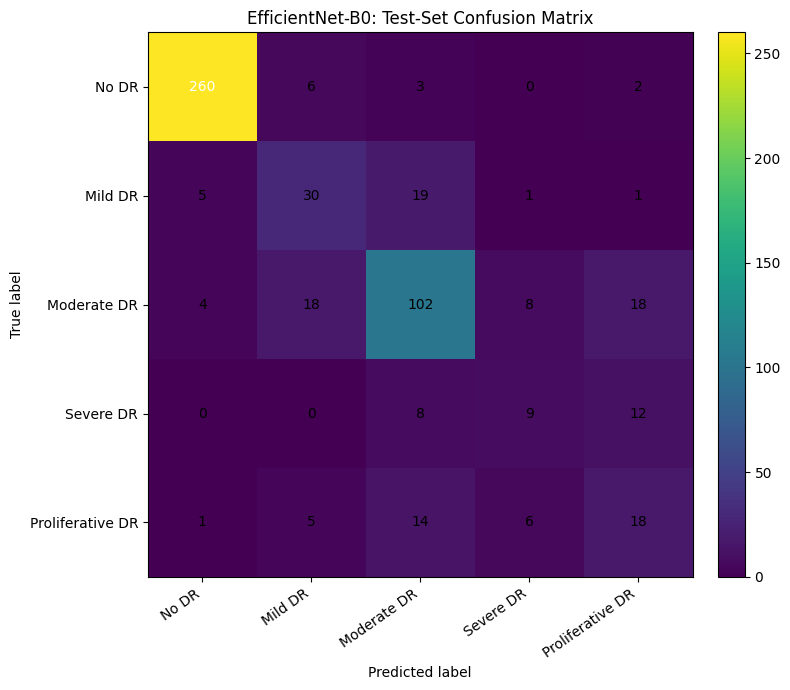

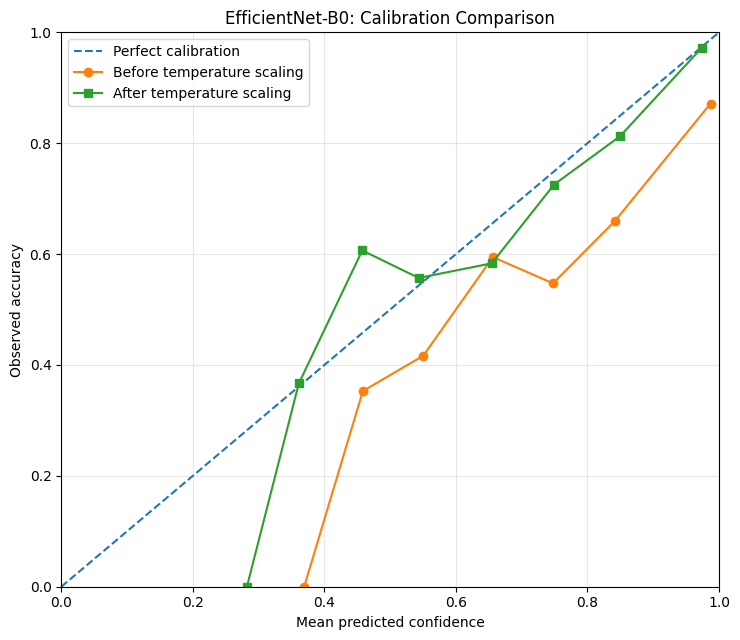


Final outputs saved in: /content/dr_paper_results/final_paper_results
ZIP package: /content/dr_paper_results/final_paper_results.zip

Files:
 - calibration_bin_data.csv
 - calibration_comparison.png
 - classwise_performance.csv
 - confusion_matrix.csv
 - confusion_matrix.png
 - experiment_metadata.json
 - final_metrics_comparison.csv


In [61]:

import os
import json
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    cohen_kappa_score,
    roc_auc_score
)

# --------------------------------------------------
# 1. File paths and class definitions
# --------------------------------------------------
base_dir = "/content/dr_paper_results"
cal_dir = os.path.join(base_dir, "temperature_scaling")
out_dir = os.path.join(base_dir, "final_paper_results")
os.makedirs(out_dir, exist_ok=True)

original_path = os.path.join(
    base_dir, "test_predictions.csv"
)
calibrated_path = os.path.join(
    cal_dir, "calibrated_test_predictions.csv"
)

assert os.path.exists(original_path), (
    f"Missing file: {original_path}"
)
assert os.path.exists(calibrated_path), (
    f"Missing file: {calibrated_path}. "
    "Run the temperature-scaling save cell first."
)

original = pd.read_csv(original_path)
calibrated = pd.read_csv(calibrated_path)

class_names = [
    "No DR",
    "Mild DR",
    "Moderate DR",
    "Severe DR",
    "Proliferative DR"
]
labels = np.arange(5)

before_cols = [
    "prob_no_dr",
    "prob_mild",
    "prob_moderate",
    "prob_severe",
    "prob_proliferative_dr"
]
after_cols = [
    "prob_after_no_dr",
    "prob_after_mild_dr",
    "prob_after_moderate_dr",
    "prob_after_severe_dr",
    "prob_after_proliferative_dr"
]

# Confirm sample alignment before comparing metrics
y_true = original["true_label"].to_numpy(dtype=int)
y_before = original["predicted_label"].to_numpy(dtype=int)

assert len(original) == len(calibrated), (
    "The two prediction files have different sample counts."
)
assert np.array_equal(
    y_true, calibrated["true_label"].to_numpy(dtype=int)
), "True labels or sample order do not match."

p_before = original[before_cols].to_numpy(dtype=float)
p_after = calibrated[after_cols].to_numpy(dtype=float)
y_after = calibrated["predicted_label_after"].to_numpy(dtype=int)

assert np.isfinite(p_before).all() and np.isfinite(p_after).all()
assert np.allclose(p_before.sum(axis=1), 1, atol=1e-3), (
    "Original probabilities do not sum to approximately 1."
)
assert np.allclose(p_after.sum(axis=1), 1, atol=1e-3), (
    "Calibrated probabilities do not sum to approximately 1."
)

# --------------------------------------------------
# 2. Metric calculation functions
# --------------------------------------------------
def calculate_ece(probs, true_labels, n_bins=10):
    confidence = probs.max(axis=1)
    predictions = probs.argmax(axis=1)
    correct = (predictions == true_labels).astype(float)
    edges = np.linspace(0, 1, n_bins + 1)
    ece = 0.0

    for i in range(n_bins):
        if i == n_bins - 1:
            mask = (
                (confidence >= edges[i]) &
                (confidence <= edges[i + 1])
            )
        else:
            mask = (
                (confidence >= edges[i]) &
                (confidence < edges[i + 1])
            )

        if mask.any():
            gap = abs(correct[mask].mean() - confidence[mask].mean())
            ece += mask.mean() * gap

    return float(ece)


def calculate_brier(probs, true_labels):
    one_hot = np.eye(probs.shape[1])[true_labels]
    return float(np.mean(np.sum((probs - one_hot) ** 2, axis=1)))


def evaluate_predictions(true_labels, predictions, probs):
    precision, recall, f1, _ = precision_recall_fscore_support(
        true_labels,
        predictions,
        labels=labels,
        zero_division=0
    )

    try:
        macro_auc = roc_auc_score(
            true_labels,
            probs,
            labels=labels,
            multi_class="ovr",
            average="macro"
        )
    except ValueError:
        macro_auc = np.nan

    return {
        "Accuracy": accuracy_score(true_labels, predictions),
        "Balanced accuracy": balanced_accuracy_score(
            true_labels, predictions
        ),
        "Macro precision": precision.mean(),
        "Macro recall": recall.mean(),
        "Macro F1": f1.mean(),
        "Weighted F1": precision_recall_fscore_support(
            true_labels, predictions, average="weighted",
            zero_division=0
        )[2],
        "Quadratic weighted kappa": cohen_kappa_score(
            true_labels, predictions, weights="quadratic"
        ),
        "Macro AUROC (OvR)": macro_auc,
        "ECE (10 bins)": calculate_ece(probs, true_labels),
        "Multiclass Brier score": calculate_brier(
            probs, true_labels
        )
    }


before_metrics = evaluate_predictions(
    y_true, y_before, p_before
)
after_metrics = evaluate_predictions(
    y_true, y_after, p_after
)

metrics_df = pd.DataFrame({
    "Metric": list(before_metrics.keys()),
    "Before temperature scaling": list(before_metrics.values()),
    "After temperature scaling": list(after_metrics.values())
})

metrics_df.to_csv(
    os.path.join(out_dir, "final_metrics_comparison.csv"),
    index=False
)

print("=== FINAL METRICS ===")
display(metrics_df.round(4))

print("\nTest samples:", len(y_true))
print("Correct before scaling:", int((y_true == y_before).sum()))
print("Correct after scaling:", int((y_true == y_after).sum()))
print("Predictions unchanged:", bool(np.array_equal(y_before, y_after)))

# --------------------------------------------------
# 3. Class-wise performance table
# --------------------------------------------------
report = classification_report(
    y_true,
    y_before,
    labels=labels,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

class_df = pd.DataFrame([
    {
        "Class": name,
        "Support": int(report[name]["support"]),
        "Precision": report[name]["precision"],
        "Recall": report[name]["recall"],
        "F1-score": report[name]["f1-score"]
    }
    for name in class_names
])

class_df.to_csv(
    os.path.join(out_dir, "classwise_performance.csv"),
    index=False
)

print("\n=== CLASS-WISE BASELINE PERFORMANCE ===")
display(class_df.round(4))

# --------------------------------------------------
# 4. Publication-ready confusion matrix
# --------------------------------------------------
cm = confusion_matrix(y_true, y_before, labels=labels)

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(cm, interpolation="nearest")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

ax.set(
    xticks=labels,
    yticks=labels,
    xticklabels=class_names,
    yticklabels=class_names,
    xlabel="Predicted label",
    ylabel="True label",
    title="EfficientNet-B0: Test-Set Confusion Matrix"
)
plt.setp(ax.get_xticklabels(), rotation=35, ha="right")

threshold = cm.max() / 2
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(
            j, i, str(cm[i, j]),
            ha="center", va="center",
            color="white" if cm[i, j] > threshold else "black"
        )

fig.tight_layout()
fig.savefig(
    os.path.join(out_dir, "confusion_matrix.png"),
    dpi=300, bbox_inches="tight"
)
plt.show()

# --------------------------------------------------
# 5. Calibration comparison plot
# --------------------------------------------------
def reliability_points(probs, true_labels, n_bins=10):
    confidence = probs.max(axis=1)
    correct = (probs.argmax(axis=1) == true_labels).astype(float)
    edges = np.linspace(0, 1, n_bins + 1)

    mean_conf, observed_acc, counts = [], [], []

    for i in range(n_bins):
        if i == n_bins - 1:
            mask = (
                (confidence >= edges[i]) &
                (confidence <= edges[i + 1])
            )
        else:
            mask = (
                (confidence >= edges[i]) &
                (confidence < edges[i + 1])
            )

        if mask.any():
            mean_conf.append(confidence[mask].mean())
            observed_acc.append(correct[mask].mean())
            counts.append(mask.sum())

    return (
        np.array(mean_conf),
        np.array(observed_acc),
        np.array(counts)
    )

conf_b, acc_b, count_b = reliability_points(p_before, y_true)
conf_a, acc_a, count_a = reliability_points(p_after, y_true)

fig, ax = plt.subplots(figsize=(7.5, 6.5))
ax.plot(
    [0, 1], [0, 1], "--",
    label="Perfect calibration"
)
ax.plot(
    conf_b, acc_b, "o-",
    label="Before temperature scaling"
)
ax.plot(
    conf_a, acc_a, "s-",
    label="After temperature scaling"
)

ax.set(
    xlabel="Mean predicted confidence",
    ylabel="Observed accuracy",
    title="EfficientNet-B0: Calibration Comparison",
    xlim=(0, 1),
    ylim=(0, 1)
)
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig(
    os.path.join(out_dir, "calibration_comparison.png"),
    dpi=300, bbox_inches="tight"
)
plt.show()

# Save bin data to support reproducibility
bin_rows = []
for stage, conf, acc, counts in [
    ("Before", conf_b, acc_b, count_b),
    ("After", conf_a, acc_a, count_a)
]:
    for c, a, n in zip(conf, acc, counts):
        bin_rows.append({
            "Stage": stage,
            "Mean confidence": c,
            "Observed accuracy": a,
            "Bin sample count": int(n)
        })

pd.DataFrame(bin_rows).to_csv(
    os.path.join(out_dir, "calibration_bin_data.csv"),
    index=False
)

# --------------------------------------------------
# 6. Save confusion matrix and experiment metadata
# --------------------------------------------------
pd.DataFrame(
    cm,
    index=class_names,
    columns=class_names
).to_csv(os.path.join(out_dir, "confusion_matrix.csv"))

metadata = {
    "dataset_samples": int(len(y_true)),
    "classes": class_names,
    "temperature": 2.2509,
    "calibration_method": "Temperature scaling",
    "temperature_fitted_on": "Validation set",
    "calibration_metrics_bins": 10,
    "note": (
        "Confirm the checkpoint, split, preprocessing, "
        "and validation-only fitting before publication."
    )
}

with open(
    os.path.join(out_dir, "experiment_metadata.json"), "w"
) as f:
    json.dump(metadata, f, indent=2)

# --------------------------------------------------
# 7. Package tables and figures
# --------------------------------------------------
zip_path = os.path.join(
    base_dir, "final_paper_results.zip"
)

with zipfile.ZipFile(
    zip_path, "w", zipfile.ZIP_DEFLATED
) as archive:
    for filename in os.listdir(out_dir):
        full_path = os.path.join(out_dir, filename)
        if os.path.isfile(full_path):
            archive.write(full_path, arcname=filename)

print("\nFinal outputs saved in:", out_dir)
print("ZIP package:", zip_path)
print("\nFiles:")
for filename in sorted(os.listdir(out_dir)):
    print(" -", filename)
